In [18]:
# Environment and path setup is handled in the next cell.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
import math
import sys
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")
print(f"Files available: {os.listdir(utils_path)}")

Arquivos disponíveis em utils: ['pruning.py', 'utility_reset.py', 'filtered_paths.py', 'region_checks.py', '__pycache__', 'intersection_utils.py', 'point_generator.py', 'path_analysis.py', 'plotting.py', 'nextSteps.txt', 'test_paths_in_subregions.ipynb', 'testing_data_structures.ipynb', 'testing_points_in_subregions.ipynb', 'PiaNo.ipynb', 'testing_paths.ipynb', 'test_simple_percolation.ipynb', 'node_edge_mapping_analysis.ipynb', 'node_edge_visualization_with_ids.ipynb']


In [20]:
from point_generator import *
from region_checks import *
from intersection_utils import *
from path_analysis import *
from plotting import *
from pruning import *
from filtered_paths import *
from utility_reset import *
#from predefined_networks import *
#from tests import *

# **Executing the Experiment**

In [21]:
# Variáveis principais
a = 0.70
N = 30

points_1 = []
points_2 = []
angles = []
graph = [] #arestas
nodes = []
intersected_line_1 = []
intersected_line_2 = []
intersections_points = []
all_connected_nodes = []
solutions = []
A = []
L = []
paths = []

In [22]:
generate_points(N, points_1, points_2, angles, a)

In [23]:
intersections_points, intersected_line_1, intersected_line_2, graph = identify_intersections(points_1, points_2, intersections_points, intersected_line_1, intersected_line_2, graph, angles, a, N)

In [24]:
len(intersections_points)

61

In [25]:
boundary_condition_source = []
boundary_condition_drain = []

In [26]:
for i in range(len(intersections_points)):
  if intersections_points[i][0] < 0.1:
    boundary_condition_source.append(i)
  elif intersections_points[i][0] > 0.9:
    boundary_condition_drain.append(i)

In [27]:
print("Number of identified intersection points =", len(intersections_points))
print("In the source contact region =", len(boundary_condition_source))
print("In the drain contact region =", len(boundary_condition_drain))
print(boundary_condition_source)

Number of identified intersection points = 61
In the source contact region = 1
In the drain contact region = 3
[3]


In [28]:
path_nodes, path_pairs_of_lines, path_pairs_of_edges, all_path_perc = [], [], [], []

In [29]:
for i in boundary_condition_source:
  do_not_check = 0
  number_path = len(all_connected_nodes)
  for k in range(0,number_path):
    if i in all_connected_nodes[k]:
      do_not_check = 1
  if do_not_check == 0:
    print(f"Path number = {number_path}")
    print(f"node = {i}")
    start_node = i
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(intersections_points, graph, start_node)
    path_nodes.append(nodes)
    path_pairs_of_lines.append(pair_of_lines)
    path_pairs_of_edges.append(pair_of_edges,)
    all_path_perc.append(path_perc)
  # print(f"All nodes = {all_connected_nodes}")
  # print(f"All lines = {pair_of_lines}")

Path number = 0
node = 3
valor de queue antes = deque([3])
valor de queue depois = deque([])
nós visitados {3}
valor de target edge = (3, 11)
valor de path_pairs_of_lines = [(3, 11)]
valor do i = 1
valor do current node = 3
valor da queue após append = deque([1])
valor do path_pairs_of_nodes[3, 1]
valor do path_pairs_of_lines = [(3, 11), (0, 11)]
valor do path_pairs_of_edges = [(3, 1)]
valor do i = 2
valor do current node = 3
valor da queue após append = deque([1, 2])
valor do path_pairs_of_nodes[3, 1, 2]
valor do path_pairs_of_lines = [(3, 11), (0, 11), (3, 8)]
valor do path_pairs_of_edges = [(3, 1), (3, 2)]
valor do i = 4
valor do current node = 3
valor da queue após append = deque([1, 2, 4])
valor do path_pairs_of_nodes[3, 1, 2, 4]
valor do path_pairs_of_lines = [(3, 11), (0, 11), (3, 8), (3, 16)]
valor do path_pairs_of_edges = [(3, 1), (3, 2), (3, 4)]
valor do i = 5
valor do current node = 3
valor da queue após append = deque([1, 2, 4, 5])
valor do path_pairs_of_nodes[3, 1, 2, 4, 5

In [30]:
print(path_nodes) #create list of the correspoding pairs of edges
print(path_pairs_of_lines) #check what it is
print(path_pairs_of_edges) #create list of the correspoding nodes
print(all_path_perc)

[[3, 1, 2, 4, 5, 22, 0, 48, 18, 24, 35, 36, 39, 49, 59, 28, 47, 50, 60, 15, 16, 17, 19, 20, 21, 23, 25, 26, 27, 12, 13, 56, 58, 44, 45, 46, 37, 38, 40, 57, 6, 7, 8, 9, 10, 34, 43, 41, 11, 54, 55, 14, 51, 29, 33, 30, 32, 42, 52, 53, 31]]
[[(3, 11), (0, 11), (3, 8), (3, 16), (3, 25), (11, 8), (0, 8), (25, 8), (9, 16), (12, 16), (16, 6), (16, 23), (18, 16), (25, 16), (29, 16), (12, 25), (25, 6), (25, 23), (29, 25), (9, 2), (9, 4), (9, 10), (9, 18), (9, 22), (9, 23), (12, 2), (12, 18), (12, 19), (12, 23), (5, 6), (6, 1), (28, 6), (29, 6), (23, 1), (23, 2), (23, 19), (18, 2), (18, 7), (18, 21), (29, 2), (4, 1), (4, 17), (4, 19), (4, 22), (4, 27), (15, 22), (22, 17), (19, 1), (5, 1), (27, 1), (28, 1), (7, 24), (26, 7), (13, 21), (15, 17), (13, 24), (14, 24), (20, 24), (26, 13), (26, 20), (14, 20)]]
[[(3, 1), (3, 2), (3, 4), (3, 5), (3, 22), (1, 0), (2, 48), (4, 18), (4, 24), (4, 35), (4, 36), (4, 39), (4, 49), (4, 59), (5, 28), (5, 47), (5, 50), (5, 60), (18, 15), (18, 16), (18, 17), (18, 19

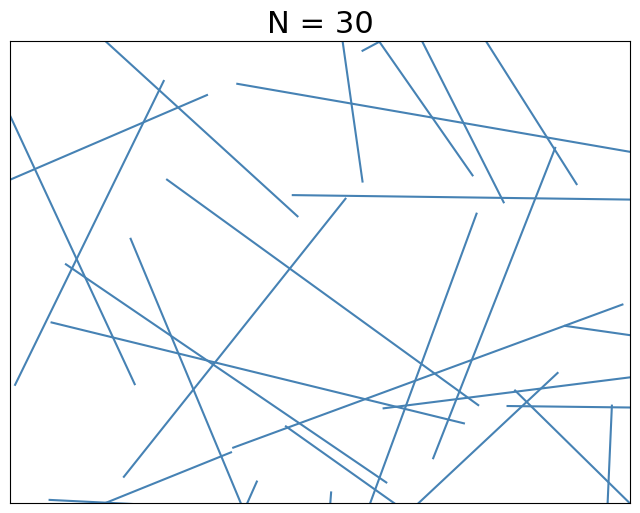

In [31]:
plot_lines(N, points_1, points_2)

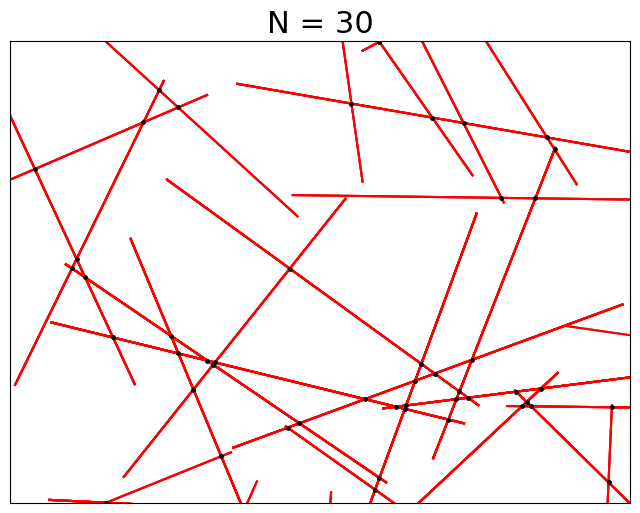

In [32]:
plot_lines_intersection(N, points_1, points_2, intersected_line_1, intersected_line_2, intersections_points)

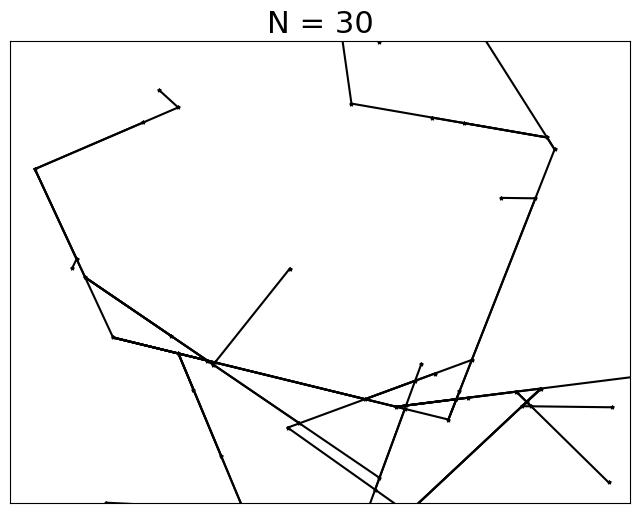

In [33]:
plot_only_paths(N, intersections_points, path_nodes, path_pairs_of_edges)

1


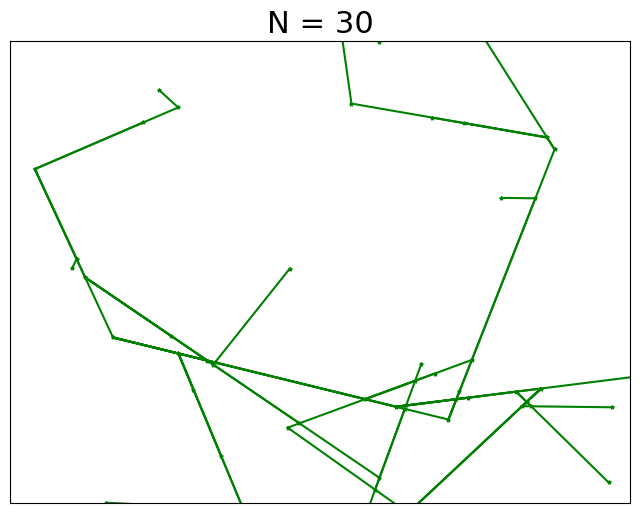

In [34]:
plot_percolating_paths(N, intersections_points, path_nodes, path_pairs_of_edges, all_path_perc)

# **Node-Edge Mapping Analysis**

This section creates two complementary data structures to analyze the relationship between nodes and edge pairs in the percolation paths.

## Data Structure 1: Node → Edge Pairs Mapping

**Purpose**: Given a node (intersection point), find all edge pairs that include this node.

**Structure**: `{node_id: [list of edge_pairs that contain this node]}`

**Use case**: When you want to know "What connections involve this specific intersection point?"

In [35]:
def create_node_to_edges_mapping(path_nodes, path_pairs_of_edges):
    """
    Creates a mapping from nodes to edge pairs.

    Args:
        path_nodes: List of lists, where each inner list contains node indices for one path
        path_pairs_of_edges: List of lists, where each inner list contains edge tuples for one path

    Returns:
        node_to_edges: Dictionary mapping node_id -> list of edge pairs containing that node

    Example:
        If node 5 appears in edges (3,5) and (5,7), then:
        node_to_edges[5] = [(3,5), (5,7)]
    """
    node_to_edges = {}

    # Iterate through all paths
    for path_idx in range(len(path_pairs_of_edges)):
        edges = path_pairs_of_edges[path_idx]

        # For each edge pair in this path
        for edge_pair in edges:
            if isinstance(edge_pair, tuple) and len(edge_pair) == 2:
                node1, node2 = edge_pair

                # Add this edge pair to node1's list
                if node1 not in node_to_edges:
                    node_to_edges[node1] = []
                if edge_pair not in node_to_edges[node1]:
                    node_to_edges[node1].append(edge_pair)

                # Add this edge pair to node2's list
                if node2 not in node_to_edges:
                    node_to_edges[node2] = []
                if edge_pair not in node_to_edges[node2]:
                    node_to_edges[node2].append(edge_pair)

    return node_to_edges

In [36]:
# Create the node to edges mapping
node_to_edges = create_node_to_edges_mapping(path_nodes, path_pairs_of_edges)

print("=" * 70)
print("DATA STRUCTURE 1: Node → Edge Pairs Mapping")
print("=" * 70)
print(f"Total nodes involved in paths: {len(node_to_edges)}\n")

# Show first 10 nodes
for idx, (node, edges) in enumerate(sorted(node_to_edges.items())[:10]):
    print(f"Node {node}: participates in {len(edges)} edge(s)")
    for edge in edges:
        print(f"  └─ Edge: {edge}")

DATA STRUCTURE 1: Node → Edge Pairs Mapping
Total nodes involved in paths: 61

Node 0: participates in 1 edge(s)
  └─ Edge: (1, 0)
Node 1: participates in 2 edge(s)
  └─ Edge: (3, 1)
  └─ Edge: (1, 0)
Node 2: participates in 2 edge(s)
  └─ Edge: (3, 2)
  └─ Edge: (2, 48)
Node 3: participates in 5 edge(s)
  └─ Edge: (3, 1)
  └─ Edge: (3, 2)
  └─ Edge: (3, 4)
  └─ Edge: (3, 5)
  └─ Edge: (3, 22)
Node 4: participates in 8 edge(s)
  └─ Edge: (3, 4)
  └─ Edge: (4, 18)
  └─ Edge: (4, 24)
  └─ Edge: (4, 35)
  └─ Edge: (4, 36)
  └─ Edge: (4, 39)
  └─ Edge: (4, 49)
  └─ Edge: (4, 59)
Node 5: participates in 5 edge(s)
  └─ Edge: (3, 5)
  └─ Edge: (5, 28)
  └─ Edge: (5, 47)
  └─ Edge: (5, 50)
  └─ Edge: (5, 60)
Node 6: participates in 1 edge(s)
  └─ Edge: (16, 6)
Node 7: participates in 2 edge(s)
  └─ Edge: (16, 7)
  └─ Edge: (7, 33)
Node 8: participates in 1 edge(s)
  └─ Edge: (16, 8)
Node 9: participates in 1 edge(s)
  └─ Edge: (16, 9)


## Data Structure 2: Edge Pair → Connecting Node Mapping

**Purpose**: Given an edge pair (tuple of two nodes), identify which nodes form this connection.

**Structure**: `{(node_i, node_j): (node_i, node_j)}`

**Use case**: When you want to know "Which two nodes are connected by this edge?"

**Note**: This also provides a quick way to check if a specific edge exists in the network.

In [37]:
def create_edge_to_nodes_mapping(path_pairs_of_edges):
    """
    Creates a mapping from edge pairs to their constituent nodes.

    Args:
        path_pairs_of_edges: List of lists, where each inner list contains edge tuples for one path

    Returns:
        edge_to_nodes: Dictionary mapping edge_pair -> tuple of (node1, node2)

    Example:
        edge_to_nodes[(3,5)] = (3, 5)
        This tells you that edge (3,5) connects nodes 3 and 5
    """
    edge_to_nodes = {}

    # Iterate through all paths
    for path_idx in range(len(path_pairs_of_edges)):
        edges = path_pairs_of_edges[path_idx]

        # For each edge pair in this path
        for edge_pair in edges:
            if isinstance(edge_pair, tuple) and len(edge_pair) == 2:
                # Store the edge and its constituent nodes
                if edge_pair not in edge_to_nodes:
                    edge_to_nodes[edge_pair] = (edge_pair[0], edge_pair[1])

    return edge_to_nodes

In [38]:
# Create the edge to nodes mapping
edge_to_nodes = create_edge_to_nodes_mapping(path_pairs_of_edges)

print("=" * 70)
print("DATA STRUCTURE 2: Edge Pair → Nodes Mapping")
print("=" * 70)
print(f"Total unique edges in paths: {len(edge_to_nodes)}\n")

# Show first 10 edges
for idx, (edge, nodes) in enumerate(list(edge_to_nodes.items())[:10]):
    print(f"Edge {edge}: connects nodes {nodes[0]} ← → {nodes[1]}")

DATA STRUCTURE 2: Edge Pair → Nodes Mapping
Total unique edges in paths: 60

Edge (3, 1): connects nodes 3 ← → 1
Edge (3, 2): connects nodes 3 ← → 2
Edge (3, 4): connects nodes 3 ← → 4
Edge (3, 5): connects nodes 3 ← → 5
Edge (3, 22): connects nodes 3 ← → 22
Edge (1, 0): connects nodes 1 ← → 0
Edge (2, 48): connects nodes 2 ← → 48
Edge (4, 18): connects nodes 4 ← → 18
Edge (4, 24): connects nodes 4 ← → 24
Edge (4, 35): connects nodes 4 ← → 35


## Detailed Path Analysis

Let's examine each path individually to see the node-edge relationships.

In [39]:
print("=" * 70)
print("DETAILED PATH-BY-PATH ANALYSIS")
print("=" * 70)

for path_idx in range(len(path_nodes)):
    print(f"\n{'='*70}")
    print(f"PATH {path_idx + 1}")
    print(f"{'='*70}")

    nodes = path_nodes[path_idx]
    edges = path_pairs_of_edges[path_idx]

    print(f"Total nodes in path: {len(nodes)}")
    print(f"Nodes: {nodes}\n")

    print(f"Total edges in path: {len(edges)}")
    print(f"Edges: {edges}\n")

    # Show which nodes participate in which edges
    print("Node participation in edges:")
    for node in nodes:
        node_edges = [e for e in edges if node in e]
        if node_edges:
            print(f"  Node {node}: appears in {len(node_edges)} edge(s) → {node_edges}")

    print("\nEdge-by-edge traversal:")
    for edge_idx, edge in enumerate(edges):
        print(f"  Step {edge_idx + 1}: {edge[0]} → {edge[1]}")

DETAILED PATH-BY-PATH ANALYSIS

PATH 1
Total nodes in path: 61
Nodes: [3, 1, 2, 4, 5, 22, 0, 48, 18, 24, 35, 36, 39, 49, 59, 28, 47, 50, 60, 15, 16, 17, 19, 20, 21, 23, 25, 26, 27, 12, 13, 56, 58, 44, 45, 46, 37, 38, 40, 57, 6, 7, 8, 9, 10, 34, 43, 41, 11, 54, 55, 14, 51, 29, 33, 30, 32, 42, 52, 53, 31]

Total edges in path: 60
Edges: [(3, 1), (3, 2), (3, 4), (3, 5), (3, 22), (1, 0), (2, 48), (4, 18), (4, 24), (4, 35), (4, 36), (4, 39), (4, 49), (4, 59), (5, 28), (5, 47), (5, 50), (5, 60), (18, 15), (18, 16), (18, 17), (18, 19), (18, 20), (18, 21), (24, 23), (24, 25), (24, 26), (24, 27), (35, 12), (35, 13), (35, 56), (35, 58), (36, 44), (36, 45), (36, 46), (39, 37), (39, 38), (39, 40), (59, 57), (16, 6), (16, 7), (16, 8), (16, 9), (16, 10), (20, 34), (20, 43), (26, 41), (12, 11), (13, 54), (13, 55), (38, 14), (38, 51), (40, 29), (7, 33), (14, 30), (14, 32), (14, 42), (51, 52), (51, 53), (32, 31)]

Node participation in edges:
  Node 3: appears in 5 edge(s) → [(3, 1), (3, 2), (3, 4), (3

## Query Functions

Utility functions to easily query the data structures.

In [40]:
def query_node(node_id, node_to_edges):
    """
    Query which edge pairs involve a specific node.
    """
    print(f"\nQUERY: Which edges involve Node {node_id}?")
    print("=" * 50)

    if node_id in node_to_edges:
        edges = node_to_edges[node_id]
        print(f"Node {node_id} participates in {len(edges)} edge(s):\n")

        for edge in edges:
            other_node = edge[1] if edge[0] == node_id else edge[0]
            print(f"  • Edge {edge}: Node {node_id} ← → Node {other_node}")

        return edges
    else:
        print(f"Node {node_id} not found in any path edges.")
        return None


def query_edge(edge_pair, edge_to_nodes):
    """
    Query which nodes form a specific edge.
    """
    print(f"\nQUERY: Which nodes form Edge {edge_pair}?")
    print("=" * 50)

    if edge_pair in edge_to_nodes:
        nodes = edge_to_nodes[edge_pair]
        print(f"Edge {edge_pair} connects:")
        print(f"  • Node {nodes[0]}")
        print(f"  • Node {nodes[1]}")
        return nodes
    else:
        print(f"Edge {edge_pair} not found in the network.")
        return None


def find_path_containing_node(node_id, path_nodes, path_pairs_of_edges):
    """
    Find which path(s) contain a specific node.
    """
    print(f"\nQUERY: Which path(s) contain Node {node_id}?")
    print("=" * 50)

    paths_found = []

    for path_idx, nodes in enumerate(path_nodes):
        if node_id in nodes:
            paths_found.append(path_idx)
            print(f"\n  Path {path_idx + 1}:")
            print(f"    Nodes: {nodes}")
            print(f"    Edges: {path_pairs_of_edges[path_idx]}")

    if not paths_found:
        print(f"Node {node_id} not found in any path.")

    return paths_found

## Example Queries

In [41]:
# Example 1: Query a node
if len(node_to_edges) > 0:
    example_node = list(node_to_edges.keys())[0]
    query_node(example_node, node_to_edges)


QUERY: Which edges involve Node 3?
Node 3 participates in 5 edge(s):

  • Edge (3, 1): Node 3 ← → Node 1
  • Edge (3, 2): Node 3 ← → Node 2
  • Edge (3, 4): Node 3 ← → Node 4
  • Edge (3, 5): Node 3 ← → Node 5
  • Edge (3, 22): Node 3 ← → Node 22


In [42]:
# Example 2: Query an edge
if len(edge_to_nodes) > 0:
    example_edge = list(edge_to_nodes.keys())[0]
    query_edge(example_edge, edge_to_nodes)


QUERY: Which nodes form Edge (3, 1)?
Edge (3, 1) connects:
  • Node 3
  • Node 1


In [43]:
# Example 3: Find paths containing a specific node
if len(path_nodes) > 0 and len(path_nodes[0]) > 0:
    example_node = path_nodes[0][0]
    find_path_containing_node(example_node, path_nodes, path_pairs_of_edges)


QUERY: Which path(s) contain Node 3?

  Path 1:
    Nodes: [3, 1, 2, 4, 5, 22, 0, 48, 18, 24, 35, 36, 39, 49, 59, 28, 47, 50, 60, 15, 16, 17, 19, 20, 21, 23, 25, 26, 27, 12, 13, 56, 58, 44, 45, 46, 37, 38, 40, 57, 6, 7, 8, 9, 10, 34, 43, 41, 11, 54, 55, 14, 51, 29, 33, 30, 32, 42, 52, 53, 31]
    Edges: [(3, 1), (3, 2), (3, 4), (3, 5), (3, 22), (1, 0), (2, 48), (4, 18), (4, 24), (4, 35), (4, 36), (4, 39), (4, 49), (4, 59), (5, 28), (5, 47), (5, 50), (5, 60), (18, 15), (18, 16), (18, 17), (18, 19), (18, 20), (18, 21), (24, 23), (24, 25), (24, 26), (24, 27), (35, 12), (35, 13), (35, 56), (35, 58), (36, 44), (36, 45), (36, 46), (39, 37), (39, 38), (39, 40), (59, 57), (16, 6), (16, 7), (16, 8), (16, 9), (16, 10), (20, 34), (20, 43), (26, 41), (12, 11), (13, 54), (13, 55), (38, 14), (38, 51), (40, 29), (7, 33), (14, 30), (14, 32), (14, 42), (51, 52), (51, 53), (32, 31)]


## Network Statistics

In [44]:
print("=" * 70)
print("NETWORK STATISTICS")
print("=" * 70)

print(f"\nTotal paths found: {len(path_nodes)}")
print(f"Total unique nodes in all paths: {len(node_to_edges)}")
print(f"Total unique edges in all paths: {len(edge_to_nodes)}")

# Node degree distribution (how many edges each node participates in)
degree_distribution = {}
for node, edges in node_to_edges.items():
    degree = len(edges)
    if degree not in degree_distribution:
        degree_distribution[degree] = 0
    degree_distribution[degree] += 1

print("\nNode Degree Distribution:")
for degree in sorted(degree_distribution.keys()):
    count = degree_distribution[degree]
    print(f"  {count} node(s) with degree {degree} (participates in {degree} edge(s))")

# Find highly connected nodes (hubs)
node_degrees = [(node, len(edges)) for node, edges in node_to_edges.items()]
node_degrees.sort(key=lambda x: x[1], reverse=True)

print("\nTop 5 Most Connected Nodes (Hubs):")
for node, degree in node_degrees[:5]:
    print(f"  Node {node}: degree {degree}")
    print(f"    Edges: {node_to_edges[node]}")

NETWORK STATISTICS

Total paths found: 1
Total unique nodes in all paths: 61
Total unique edges in all paths: 60

Node Degree Distribution:
  39 node(s) with degree 1 (participates in 1 edge(s))
  8 node(s) with degree 2 (participates in 2 edge(s))
  4 node(s) with degree 3 (participates in 3 edge(s))
  3 node(s) with degree 4 (participates in 4 edge(s))
  4 node(s) with degree 5 (participates in 5 edge(s))
  1 node(s) with degree 6 (participates in 6 edge(s))
  1 node(s) with degree 7 (participates in 7 edge(s))
  1 node(s) with degree 8 (participates in 8 edge(s))

Top 5 Most Connected Nodes (Hubs):
  Node 4: degree 8
    Edges: [(3, 4), (4, 18), (4, 24), (4, 35), (4, 36), (4, 39), (4, 49), (4, 59)]
  Node 18: degree 7
    Edges: [(4, 18), (18, 15), (18, 16), (18, 17), (18, 19), (18, 20), (18, 21)]
  Node 16: degree 6
    Edges: [(18, 16), (16, 6), (16, 7), (16, 8), (16, 9), (16, 10)]
  Node 3: degree 5
    Edges: [(3, 1), (3, 2), (3, 4), (3, 5), (3, 22)]
  Node 5: degree 5
    Edges

## Verification: Cross-check Data Structures

Let's verify that both data structures are consistent with each other.

In [45]:
print("=" * 70)
print("VERIFICATION: Cross-checking data structures")
print("=" * 70)

# Check 1: Every edge in edge_to_nodes should have both nodes in node_to_edges
print("\nCheck 1: Verifying edge-node consistency...")
inconsistencies = 0

for edge, (node1, node2) in edge_to_nodes.items():
    if node1 not in node_to_edges:
        print(f"  ERROR: Node {node1} from edge {edge} not in node_to_edges")
        inconsistencies += 1
    elif edge not in node_to_edges[node1]:
        print(f"  ERROR: Edge {edge} not listed for node {node1}")
        inconsistencies += 1

    if node2 not in node_to_edges:
        print(f"  ERROR: Node {node2} from edge {edge} not in node_to_edges")
        inconsistencies += 1
    elif edge not in node_to_edges[node2]:
        print(f"  ERROR: Edge {edge} not listed for node {node2}")
        inconsistencies += 1

if inconsistencies == 0:
    print("  ✓ All edges are consistent with node mappings")
else:
    print(f"  ✗ Found {inconsistencies} inconsistencies")

# Check 2: Count total edges from both perspectives
print("\nCheck 2: Counting edges from different perspectives...")
edges_from_edge_dict = len(edge_to_nodes)
edges_from_node_dict = sum(len(edges) for edges in node_to_edges.values()) // 2  # Divide by 2 since each edge is counted twice

print(f"  Edges in edge_to_nodes: {edges_from_edge_dict}")
print(f"  Unique edges from node_to_edges: {edges_from_node_dict}")

if edges_from_edge_dict == edges_from_node_dict:
    print("  ✓ Edge counts match")
else:
    print(f"  ✗ Edge counts don't match (difference: {abs(edges_from_edge_dict - edges_from_node_dict)})")

print("\n" + "=" * 70)
print("Verification complete!")
print("=" * 70)

VERIFICATION: Cross-checking data structures

Check 1: Verifying edge-node consistency...
  ✓ All edges are consistent with node mappings

Check 2: Counting edges from different perspectives...
  Edges in edge_to_nodes: 60
  Unique edges from node_to_edges: 60
  ✓ Edge counts match

Verification complete!
